(pathway-activity)=
# Pathway and regulator activity

A gene-set test answers one question of one contrast. Scores answer it for every
profile: how active is a regulator or a pathway in each sample, or in each cell type's
response? A transcription factor raises some of its targets and lowers others, and a
signalling pathway leaves a footprint of genes that respond to it. CollecTRI
[@muellerdott2023] and PROGENy [@schubert2018] give each such source signed weights
on its targets, and {api}`ulm` scores the sources from them as decoupler does
[@badiaimompel2022]; GSVA scores gene sets, whose genes count alike
[@haenzelmann2013]. [Gene-set tests](../statistics/gene_set_tests.md#activities-of-regulators-and-pathways)
explains the methods. This page scores the Kang data [@kang2018] (the `kang2018`
dataset of the [Datasets](../reference/datasets.md) page).

{api}`collectri` and {api}`progeny` download their networks on first use, check them
against pinned digests and keep them in a cache. By default `collectri()` keeps the
interactions whose sources allow commercial use, the licence level a company may use
([Datasets](../reference/datasets.md#networks) gives the terms).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import cytepool
from cytepool.activity import ulm
from cytepool.design import Design
from cytepool.differential_expression import limma_voom
from cytepool.gene_sets import GeneSets
from cytepool.io import read_cube
from cytepool.networks import collectri, progeny
from cytepool.pathway_scores import gsva
from cytepool.plotting import plot_activities, plot_pathway_scores, plot_top_activities
from cytepool.stats.empirical_bayes import moderated_statistics
from cytepool.stats.linear_models import contrasts_fit, fit_linear_model
from cytepool.stats.multiple_testing import adjust_p_values

kang = read_cube("kang2018.cube.zarr")
levels = {"condition": ["ctrl", "stim"]}
contrasts = {"stim_vs_ctrl": "conditionstim"}
design = Design(kang.samples, "~ donor + condition", levels=levels, contrasts=contrasts)
result = limma_voom(kang, design)
regulators = collectri()
print(f"CytePool {cytepool.__version__}")
print(regulators)

CytePool 0.1.dev61+gcd5dbe953
Network: 1,171 sources, 39,896 edges, 6,505 target genes
  name: CollecTRI; version: 2.0 (Zenodo record 8192729); licence: CC BY 4.0
        (Zenodo record 8192729); level 'commercial': the interactions of
        resources that OmniPath lists for commercial use, without those that
        GEREDB (listed for academic use) alone supports; each resource keeps its
        own terms
  read from CollecTRI_regulons.csv, SHA-256
      4473c9189dd53dacc80297709ad1452dda1086a1cc2185f9a56146c261668701
  sources: MYC (853), SPI1 (332), SMAD3 (159) and 1,168 more


## Regulators of each cell type's response

Scored on the moderated t-statistics of a contrast, a regulator is active when its
activated targets go up and its repressed targets go down. {api}`ulm` scores every
cell type of the result, one profile each; the bars show the regulators with the
largest scores in the CD14+ monocytes, and the heatmap the 25 with the largest scores
in any cell type.

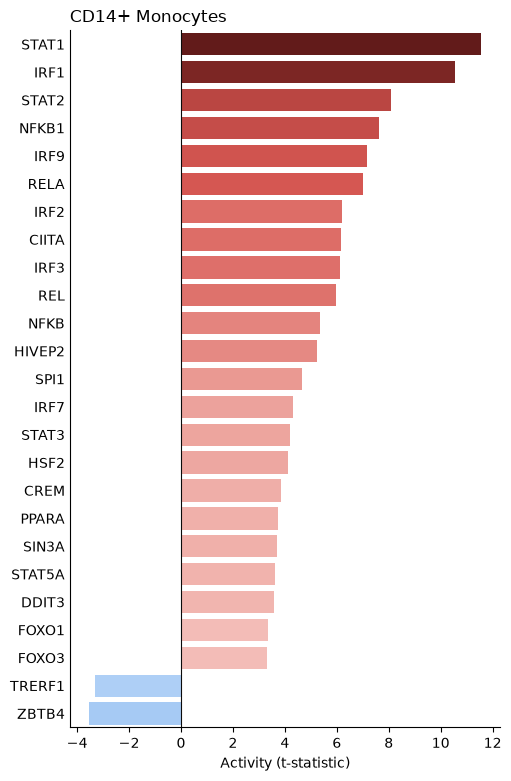

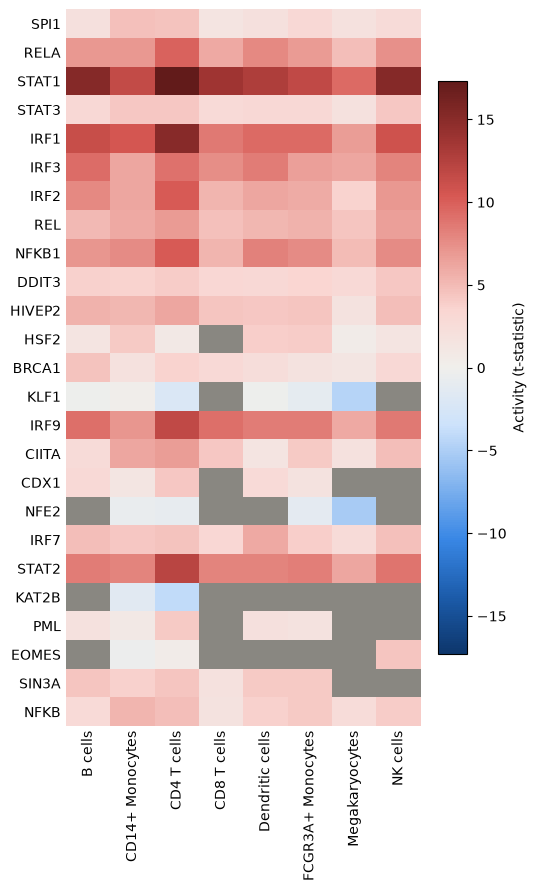

In [2]:
responses = ulm(result, regulators, id_column="symbol")
plot_top_activities(responses, "CD14+ Monocytes")
plt.show()
plot_activities(responses, top=25)
plt.show()

STAT1, IRF1 and STAT2 lead the monocytes' response, as camera ranked their targets
([Gene sets and pathways](gene_sets.ipynb)), now with each target counted with its
sign. The same regulators are active in the response of every cell type, most in the
CD4 T cells. A regulator with too few targets among a cell type's tested genes has no
score there, drawn dark grey: fewer genes pass the filter where the profiles are
small, as in the CD8 T cells and the megakaryocytes.

## Pathways in every sample

Scored on the log-CPM values of one cell type, every sample gets an activity for each
pathway, which can be drawn, compared and tested with the design like the expression
of a gene. PROGENy's footprints are those of 14 pathways in human cells.

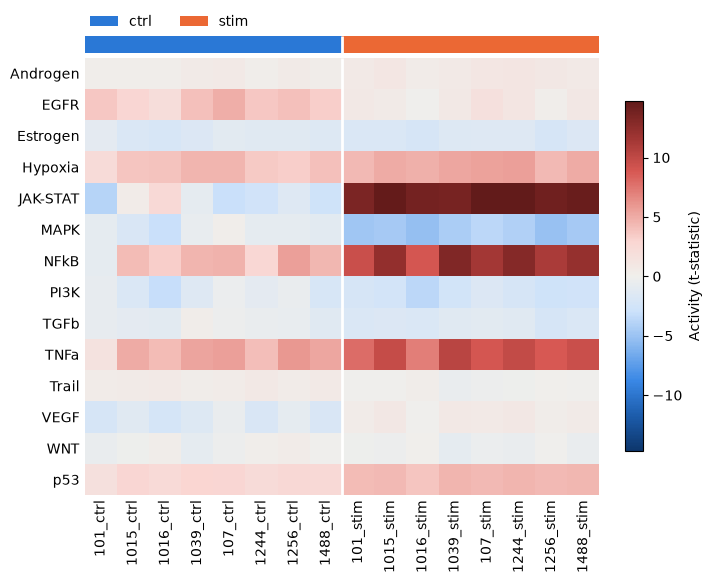

pathway         t  adjusted p
JAK-STAT     22.3     5.1e-08
NFkB         13.5     1.0e-06
p53          12.9     1.2e-06
VEGF         10.4     6.3e-06
TNFa         10.2     6.5e-06
Hypoxia       6.4     1.8e-04
Androgen      3.5     8.0e-03
WNT          -1.6     1.5e-01
Estrogen     -2.0     7.7e-02
PI3K         -5.6     4.6e-04
Trail        -6.4     1.8e-04
TGFb         -6.4     1.8e-04
EGFR        -14.4     7.8e-07
MAPK        -14.9     7.8e-07


In [3]:
pathways = ulm(kang, progeny(), group="CD14+ Monocytes", gene_ids="symbol")
plot_activities(pathways, color_by="condition")
plt.show()

profile_design = Design(
    pathways.profiles, "~ donor + condition", levels=levels, contrasts=contrasts
)
fit = contrasts_fit(
    fit_linear_model(pathways.scores, profile_design), profile_design.contrasts
)
tested = moderated_statistics(fit)
adjusted = adjust_p_values(tested.p_value[:, 0])
print(f"{'pathway':<10}{'t':>7}{'adjusted p':>12}")
for k in np.argsort(-tested.t[:, 0]):
    print(f"{pathways.sources[k]:<10}{tested.t[k, 0]:>7.1f}{adjusted[k]:>12.1e}")

JAK-STAT, through which interferons signal, rises in every stimulated sample, with
NFkB and TNFa, while MAPK and EGFR fall. The test, which pairs each donor's samples,
also finds smaller shifts that every donor shares, such as those of p53 and VEGF,
which the heatmap barely shows.

## Scores of gene sets in every sample

{api}`gsva` scores each gene set in every sample from how the set's genes rank against
the sample's other genes, each gene measured against its own distribution across the
samples. Here the sets are the regulators' targets, without their signs; as GSVA's
guide does, the scores are tested with limma, with a prior that follows the sets'
sizes, and the heatmap shows the 20 sets that differ most between the conditions.

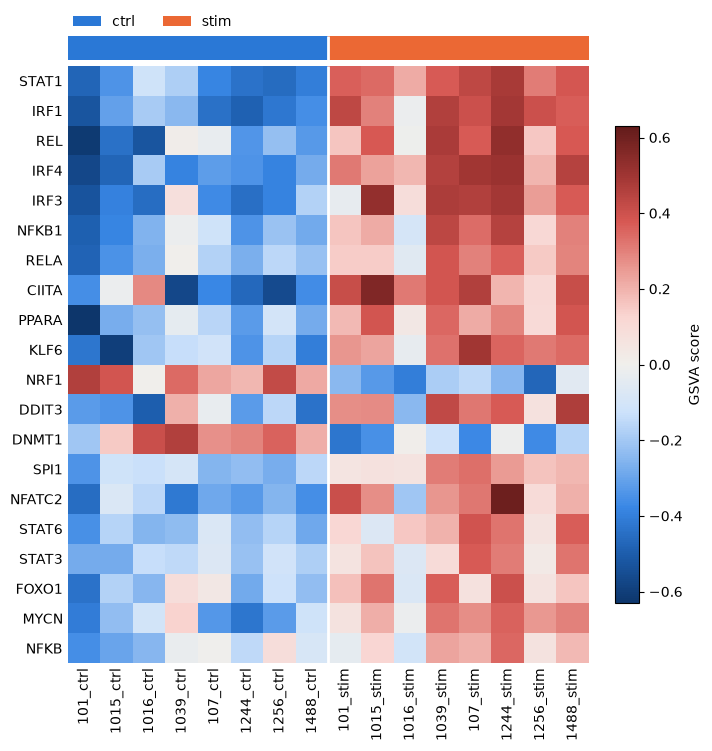

In [4]:
regulons = GeneSets(
    {regulator: list(targets) for regulator, targets in regulators.items()},
    source=regulators.name,
    licence=regulators.licence,
)
scores = gsva(
    kang,
    regulons,
    group="CD14+ Monocytes",
    gene_ids="symbol",
    min_size=15,
    max_size=500,
)
score_design = Design(
    scores.samples, "~ donor + condition", levels=levels, contrasts=contrasts
)
fit = contrasts_fit(
    fit_linear_model(scores.scores, score_design), score_design.contrasts
)
differing = np.argsort(moderated_statistics(fit, trend=scores.n_genes).p_value[:, 0])
names = list(scores.gene_sets)
plot_pathway_scores(
    scores, sets=[names[k] for k in differing[:20]], color_by="condition"
)
plt.show()

The target sets of the interferon regulators score low in the controls and high after
the stimulation. GSVA treats a set's targets alike, whether the regulator activates or
represses them; the activities above weigh them by their signs.

## Choices

- **A contrast or the samples.** Score a contrast's statistics to see which regulators
  drive a response, in each cell type; score the samples to compare them, correlate
  activities with other measurements, or test them with any design.
- **ULM, MLM or the weighted aggregate.** {api}`ulm` is decoupler's default for
  regulators and pathways alike; {api}`mlm` fits all the sources at once, which
  separates regulators whose targets overlap; {api}`weighted_aggregate` gives the
  weighted mean or sum of the targets' values, the sum being PROGENy's original score,
  with permutation p-values.
- **Activities or scores.** Activities weigh each target by its sign and weight, so
  that a repressed target counts against its regulator; GSVA and the other pathway
  scores ({api}`ssgsea`, {api}`combined_z_scores`, {api}`plage`) treat a set's genes
  alike.
- **The networks.** `collectri(licence="academic")` adds the interactions that only a
  resource listed for academic use supports. `progeny()` keeps each pathway's genes
  with a p-value below 0.05, as decoupler does, and `progeny(top=100)` the 100 most
  significant, as progeny's `getModel` does by default; `organism="mouse"` gives the
  mouse model. A source with fewer than `min_targets` targets among the genes of a
  profile (5 by default) gets no score, drawn dark grey in the heatmaps.
- **One contrast, one set.** To test whether a set responds in one contrast, the
  tests of [Gene sets and pathways](gene_sets.ipynb) use every gene's statistic and
  allow for the correlation between genes.